# Validate Before You Estimate: Labels as Measurements

* * *

<div class="alert alert-success">

### Learning Objectives

After this notebook, you will be able to:

- Explain why a classification prompt is a measurement instrument, and what changes when the codebook goes into it.
- Compare AI labels with human codes using accuracy, kappa, precision and recall, by class and by group.
- Explain why high accuracy does not guarantee an unbiased estimate or a valid comparison between groups.
- Correct an estimate with a small hand-coded sample (prediction-powered inference).
- Decide how many documents to code by hand from an interval curve.
</div>

### Icons Used in This Notebook
🔔 **Question**: A quick question to help you understand what's going on.<br>
🥊 **Challenge**: Interactive exercise. We'll work through these in the workshop!<br>
💡 **Tip**: How to do something a bit more efficiently or effectively.<br>
⚠️ **Warning**: Heads-up about tricky stuff or common mistakes.<br>
🎬 **Demo**: Showing off something more advanced, so you know what's possible!

The in-room exercises (the handout's Challenges 1 to 3) are hand-coding, betting and reading a curve. The notebook challenges below are their coding counterparts and are numbered on their own.

### Sections
1. [The Data](#data)
2. [From Codebook to Prompt](#prompt)
3. [Validate](#validate)
4. [Estimate](#estimate)
5. [How Many to Hand-Code?](#howmany)
6. [Key Points](#keypoints)

Every model call used in this notebook was run beforehand and saved in `outputs/`, so you do not need an API key. The script that produced the labels is `scripts/02_classify_titles.py`.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# The agreement metrics live in scripts/lesson_tools.py; the estimators are written out below.
sys.path.insert(0, "../scripts")
from lesson_tools import accuracy, cohen_kappa, confusion, per_class, sample_size_curve

LABELS = ["Health", "Education", "Environment", "Immigration",
          "Law and Crime", "Social Welfare", "Other"]

<a id='data'></a>

# The Data

We use bill titles from the **Comparative Agendas Project** (CAP). Every bill introduced in the U.S. Congress has been coded into a policy topic by trained human coders, which gives us an **answer key**. We keep 1,650 titles (75 per Congress, 1973 to 2016) and collapse the 21 CAP topics into seven labels.

In [2]:
bills = pd.read_csv("../data/processed/bills_sample.csv")
bills["party_name"] = bills["party"].map({100: "Democrat", 200: "Republican"})
print(bills.shape)
bills[["bill_id", "year", "party_name", "label_gold", "title"]].head()

(1650, 9)


,bill_id,year,party_name,label_gold,title
0,446946,2009,Democrat,Education,To make certain improvements in the Post-9/11 ...
1,291565,2015,Republican,Law and Crime,A bill to provide for hardship duty pay for bo...
2,269002,1980,Democrat,Other,A bill for the relief of Eileen Palmer.
3,419274,1999,Republican,Other,To direct the Secretary of Transportation to c...
4,286801,2016,Republican,Health,To direct the Secretary of Health and Human Se...


In [3]:
bills["label_gold"].value_counts(normalize=True).round(3)

label_gold
Other             0.718
Health            0.098
Law and Crime     0.056
Environment       0.047
Education         0.036
Social Welfare    0.030
Immigration       0.014
Name: proportion, dtype: float64

🔔 **Question**: "Other" is 72% of the sample. What accuracy would a classifier get if it answered "Other" for every title? Keep that number in mind.

<a id='prompt'></a>

# From Codebook to Prompt

Three prompts were written for the same task. Think of each one as a **version of a measurement instrument**:

- `prompt_1_names`: the seven category names and nothing else.
- `prompt_2_codebook`: a condensed version of the CAP codebook, with boundary rules.
- `prompt_3_codebook_examples`: the codebook plus fourteen human-coded examples drawn from **outside** the evaluation sample.

Every call asked for a fixed JSON answer: `{"label": ..., "why": ...}`. The label, the model name, the prompt version, the tokens and a timestamp were logged.

In [4]:
print(open("../prompts/prompt_2_codebook.txt").read()[:1500])

Classify the following U.S. congressional bill title into exactly one policy topic, using the codebook below. The codebook is condensed from the Comparative Agendas Project master codebook. Choose the single topic that best describes the main purpose of the bill. When a bill touches several topics, code the one that is the primary target of the bill.

CODEBOOK

Health: health care reform; health insurance, Medicare and Medicaid; the drug industry and drug approval; hospitals, clinics and other medical facilities; insurance providers; medical liability; the health care workforce; disease prevention and public health; infant and child health; mental health; long-term care; prescription drug coverage and cost; tobacco; treatment and prevention of drug and alcohol abuse; medical research.

Education: higher education and student loans; elementary and secondary schools; education for underprivileged students; vocational education; special education; educational excellence and standards; edu

In [5]:
labels = pd.read_csv("../outputs/llm_labels_clean.csv")
labels = labels.drop_duplicates(subset=["model", "prompt", "bill_id"], keep="last")
labels.groupby(["model", "prompt"]).size()

model              prompt                    
claude-haiku-5-5   prompt_1_names                1650
                   prompt_2_codebook             1650
                   prompt_3_codebook_examples    1650
claude-sonnet-5-5  prompt_3_codebook_examples    1650
dtype: int64

💡 **Tip**: Never put a document you will score inside the prompt as an example. The examples here come from a separate pool.

<a id='validate'></a>

# Validate

We merge the model labels with the human codes and compute agreement for each instrument.

In [6]:
d = labels.merge(bills, on="bill_id")
d["correct"] = d["label"] == d["label_gold"]

summary = []
for (model, prompt), g in d.groupby(["model", "prompt"]):
    summary.append({"model": model, "prompt": prompt,
                    "accuracy": accuracy(g["label_gold"], g["label"]),
                    "kappa": cohen_kappa(g["label_gold"], g["label"], LABELS)})
pd.DataFrame(summary).round(3)

,model,prompt,accuracy,kappa
0,claude-haiku-5-5,prompt_1_names,0.733,0.564
1,claude-haiku-5-5,prompt_2_codebook,0.872,0.738
2,claude-haiku-5-5,prompt_3_codebook_examples,0.875,0.742
3,claude-sonnet-5-5,prompt_3_codebook_examples,0.890,0.764


## 🥊 Notebook Challenge 1: Always "Other"

Compute the accuracy and the kappa of a classifier that answers `"Other"` for every title. Compare with the table above.

In [7]:
always_other = ["Other"] * len(bills)
print("accuracy:", round(accuracy(bills["label_gold"], always_other), 3))
print("kappa:", round(cohen_kappa(bills["label_gold"], always_other, LABELS), 3))

accuracy: 0.718
kappa: 0.0


Accuracy flatters any classifier when one class dominates. **Kappa** measures agreement beyond that chance level, which is why we report both.

## The Confusion Matrix

Rows are the human codes, columns are the model's labels (best cheap instrument: Haiku with prompt 3).

In [8]:
best = d[(d["model"] == "claude-haiku-5-5") & (d["prompt"] == "prompt_3_codebook_examples")].copy()
cm = confusion(best["label_gold"], best["label"], LABELS)
cm

model,Health,Education,Environment,Immigration,Law and Crime,Social Welfare,Other
human,,,,,,,
Health,141,1,0,0,2,1,17
Education,0,44,0,0,1,3,12
Environment,0,0,62,0,2,0,14
Immigration,1,0,0,21,0,0,1
Law and Crime,4,1,1,2,64,8,13
Social Welfare,3,0,1,0,0,37,9
Other,29,12,23,3,31,11,1075


Two questions for every category. **Precision**: when the model says Health, how often do the humans agree? **Recall**: when the humans say Health, how often does the model notice? The `per_class()` function computes both from the matrix above.

In [9]:
per_class(best["label_gold"], best["label"], LABELS).round(3)

,label,precision,recall,n_human,n_model
0,Health,0.792,0.870,162,178
1,Education,0.759,0.733,60,58
2,Environment,0.713,0.795,78,87
3,Immigration,0.808,0.913,23,26
4,Law and Crime,0.640,0.688,93,100
5,Social Welfare,0.617,0.740,50,60
6,Other,0.942,0.908,1184,1141


🔔 **Question**: Which category has the lowest recall? Where do its missed bills end up?

## 🥊 Notebook Challenge 2: Whose Error Is It?

Print five titles where the model and the humans disagree, with the model's one-sentence reason. For each, decide: is the model wrong, is the human code wrong, or is the codebook ambiguous?

In [10]:
disagreements = best[best["label"] != best["label_gold"]]
for row in disagreements.sample(5, random_state=3).itertuples():
    print(f"HUMAN: {row.label_gold:15s} MODEL: {row.label:15s}")
    print(f"  {row.title[:150]}")
    print(f"  model's reason: {row.why[:150]}\n")

HUMAN: Other           MODEL: Environment    
  To direct the Secretary of the Army to conduct a study of the feasibility of implementing flood control measures on the Manasquan River to alleviate f
  model's reason: The bill's primary purpose is flood control on a river, which falls under water-related environmental management rather than any other listed topic, s

HUMAN: Law and Crime   MODEL: Education      
  A bill to amend the Elementary and Secondary Education Act to 1965 to authorize programs of child abuse education and prevention, and to establish a d
  model's reason: The bill amends the Elementary and Secondary Education Act to authorize child abuse education and prevention programs, so its primary target is elemen

HUMAN: Environment     MODEL: Law and Crime  
  To provide for the fair and efficient judicial consideration of personal injury and wrongful death claims arising out of asbestos exposure, to ensure 
  model's reason: The bill's primary target is the judicial pro

## Differential Error

An instrument can be equally accurate for two groups and still bias the comparison between them, if the **direction** of its errors differs. We check the share of health bills by sponsor's party.

In [11]:
best["is_health_gold"] = best["label_gold"] == "Health"
best["is_health_llm"] = best["label"] == "Health"
best[best["party_name"].notna()].groupby("party_name")[["correct", "is_health_gold", "is_health_llm"]].mean().round(3)

,correct,is_health_gold,is_health_llm
party_name,,,
Democrat,0.880,0.097,0.117
Republican,0.868,0.098,0.092


⚠️ **Warning**: The humans see no partisan gap. The model creates one. Accuracy by group would not have warned you; validate the **estimate** by group, not only the labels.

<a id='estimate'></a>

# Estimate

Suppose we can afford to hand-code only 200 titles. We draw them at random. On those 200 we observe both the model's label and the truth, so we can measure the model's average error and subtract it from the model's average over all 1,650 titles. That is **prediction-powered inference** (Angelopoulos et al., 2023), and the design-based estimators of Egami et al. (2023, 2024) generalize it.

First the random hand-coded subset. The seed makes the draw reproducible; in a real project the draw is the one step you must not skip, because the correction only works if the subset is random.

In [12]:
rng = np.random.default_rng(11)
hand_idx = rng.choice(best.index, size=200, replace=False)
best["hand_coded"] = best.index.isin(hand_idx)
best["hand_coded"].sum()

np.int64(200)

Now the three estimates, written out. Each label becomes a number: 1 if the title was called Health, 0 if not, so a share is a mean.

- **Naive**: the mean of the model's labels over all N titles, with the usual interval for a mean. It ignores the model's error.
- **Hand-coded subset only**: the mean of the human codes over the n hand-coded titles. Unbiased, but only n titles wide.
- **Corrected (PPI)**: the model's mean over all N titles, minus the model's average error measured on the n hand-coded titles. The standard error adds the two pieces.

In [13]:
def estimate_naive(model_flag_all):
    f = np.asarray(model_flag_all, dtype=float)
    return f.mean(), np.sqrt(f.var(ddof=1) / len(f))

def estimate_human_only(human_flag_subset):
    y = np.asarray(human_flag_subset, dtype=float)
    return y.mean(), np.sqrt(y.var(ddof=1) / len(y))

def estimate_corrected(model_flag_all, model_flag_subset, human_flag_subset):
    f_all = np.asarray(model_flag_all, dtype=float)
    f_sub = np.asarray(model_flag_subset, dtype=float)
    y_sub = np.asarray(human_flag_subset, dtype=float)
    error = f_sub - y_sub                                   # the model's error on the hand-coded titles
    estimate = f_all.mean() - error.mean()                  # the one line
    se = np.sqrt(f_all.var(ddof=1) / len(f_all) + error.var(ddof=1) / len(error))
    return estimate, se

A small helper prints the three estimates with their 95% intervals, next to the truth we happen to know here because every title was hand-coded.

In [14]:
def three_estimates(df):
    f_all = df["is_health_llm"].astype(float).values
    sub = df[df["hand_coded"]]
    f_sub = sub["is_health_llm"].astype(float).values
    y_sub = sub["is_health_gold"].astype(float).values
    rows = {}
    rows["naive (model, all titles)"] = estimate_naive(f_all)
    rows["hand-coded subset only"] = estimate_human_only(y_sub)
    rows["corrected (PPI)"] = estimate_corrected(f_all, f_sub, y_sub)
    table = pd.DataFrame(rows, index=["estimate", "se"]).T
    table["ci_low"] = table["estimate"] - 1.96 * table["se"]
    table["ci_high"] = table["estimate"] + 1.96 * table["se"]
    table.loc["truth (all titles hand-coded)"] = [df["is_health_gold"].mean(), np.nan, np.nan, np.nan]
    return table

three_estimates(best).round(3)

,estimate,se,ci_low,ci_high
"naive (model, all titles)",0.108,0.008,0.093,0.123
hand-coded subset only,0.090,0.020,0.050,0.130
corrected (PPI),0.093,0.014,0.066,0.119
truth (all titles hand-coded),0.098,NaN,NaN,NaN


💡 **Tip**: the hand-coded-only interval above is the textbook one, which works when the share is not close to 0 or 1 and n is a few hundred. For a small group with a rare label (say 1 health bill in 63), use a Wilson interval instead; the textbook one dips below zero and runs too narrow.

The same three estimates, by sponsor's party. This is where the naive estimate goes wrong in a way that matters.

In [15]:
for party in ["Democrat", "Republican"]:
    print(party)
    print(three_estimates(best[best["party_name"] == party]).round(3), "\n")

Democrat
                               estimate     se  ci_low  ci_high
naive (model, all titles)         0.117  0.010   0.097    0.137
hand-coded subset only            0.088  0.027   0.036    0.140
corrected (PPI)                   0.091  0.018   0.055    0.126
truth (all titles hand-coded)     0.097    NaN     NaN      NaN 

Republican
                               estimate     se  ci_low  ci_high
naive (model, all titles)         0.092  0.011   0.070    0.114
hand-coded subset only            0.084  0.031   0.024    0.144
corrected (PPI)                   0.092  0.020   0.052    0.132
truth (all titles hand-coded)     0.098    NaN     NaN      NaN 



🔔 **Question**: The naive point estimates for the two parties sit 2.5 points apart, in opposite directions from the truth, and their intervals ignore the model's error. What happens to that gap after the correction? What would happen to the naive intervals if the corpus had 20,000 titles instead of 1,650?

## 🥊 Notebook Challenge 3: Another Outcome

Repeat the three estimates for the share of bills about **Education**. Does the naive estimate over- or under-state it?

In [16]:
best["is_edu_gold"] = best["label_gold"] == "Education"
best["is_edu_llm"] = best["label"] == "Education"
f_all = best["is_edu_llm"].astype(float).values
sub = best[best["hand_coded"]]
f_sub, y_sub = sub["is_edu_llm"].astype(float).values, sub["is_edu_gold"].astype(float).values
for name, (est, se) in {"naive": estimate_naive(f_all), "human only": estimate_human_only(y_sub),
                        "corrected": estimate_corrected(f_all, f_sub, y_sub)}.items():
    print(f"{name:12s} {est:.3f}  ({est - 1.96 * se:.3f}, {est + 1.96 * se:.3f})")
print(f"{'truth':12s} {best['is_edu_gold'].mean():.3f}")

naive        0.035  (0.026, 0.044)
human only   0.025  (0.003, 0.047)
corrected    0.030  (0.006, 0.054)
truth        0.036


<a id='howmany'></a>

# How Many to Hand-Code?

The corrected interval narrows as the hand-coded sample grows. We resample the subset at several sizes and plot the half-width of the 95% interval.

In [17]:
sizes = [25, 50, 100, 200, 400, 800]
curve = sample_size_curve(best["is_health_llm"].astype(float).values,
                          best["is_health_llm"].astype(float).values,
                          best["is_health_gold"].astype(float).values, sizes, reps=200)
curve.round(4)

,n_hand_coded,se,ci_halfwidth
0,25,0.0328,0.0643
1,50,0.0254,0.0499
2,100,0.0199,0.0389
3,200,0.0150,0.0294
4,400,0.0121,0.0237
5,800,0.0101,0.0198


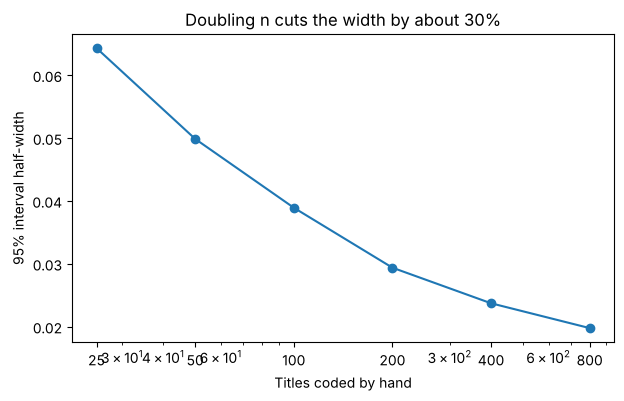

In [18]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(curve["n_hand_coded"], curve["ci_halfwidth"], marker="o")
ax.set_xscale("log")
ax.set_xticks(sizes, [str(s) for s in sizes])
ax.set_xlabel("Titles coded by hand")
ax.set_ylabel("95% interval half-width")
ax.set_title("Doubling n cuts the width by about 30%")
plt.show()

The two variances in the standard error are all you need to **project the curve to a bigger corpus**: the variance of the model flag over all N documents, and the variance of the model-minus-human difference over the n hand-coded ones. In your own project you would estimate both from a pilot of about 100 hand-coded documents.

In [19]:
var_f = best["is_health_llm"].astype(float).var(ddof=1)
var_r = (best["is_health_llm"].astype(float) - best["is_health_gold"].astype(float)).var(ddof=1)

def halfwidth(n, N=10_000):
    """Half-width of the 95% corrected interval with n hand-coded documents out of N."""
    return 1.96 * np.sqrt(var_f / N + var_r / n)

for n in [100, 200, 300, 400, 800]:
    print(f"n = {n:4d}: plus or minus {halfwidth(n):.1%}   (hand-coded sample alone: {1.96 * np.sqrt(best['is_health_gold'].mean() * (1 - best['is_health_gold'].mean()) / n):.1%})")

n =  100: plus or minus 3.7%   (hand-coded sample alone: 5.8%)
n =  200: plus or minus 2.7%   (hand-coded sample alone: 4.1%)
n =  300: plus or minus 2.2%   (hand-coded sample alone: 3.4%)
n =  400: plus or minus 1.9%   (hand-coded sample alone: 2.9%)
n =  800: plus or minus 1.4%   (hand-coded sample alone: 2.1%)


🔔 **Question**: Your committee wants to know whether Democrats and Republicans differ by 3 points or more in the share of health bills, in a corpus of 20,000 titles. To tell a 3-point gap between two groups from zero, each group's interval must be about plus or minus 2 points or narrower. How many titles per party would you hand-code, and how many hours is that at 100 titles an hour? What would it cost without the model?

🎬 **Demo**: the correction works for a difference between two groups too. The corrected gap is the difference of the two corrected shares, and its standard error combines the two.

In [20]:
gaps = {}
for party in ["Democrat", "Republican"]:
    df = best[best["party_name"] == party]
    sub = df[df["hand_coded"]]
    gaps[party] = estimate_corrected(df["is_health_llm"].astype(float).values,
                                     sub["is_health_llm"].astype(float).values,
                                     sub["is_health_gold"].astype(float).values)
gap = gaps["Democrat"][0] - gaps["Republican"][0]
gap_se = np.sqrt(gaps["Democrat"][1] ** 2 + gaps["Republican"][1] ** 2)
naive_gap = best[best["party_name"] == "Democrat"]["is_health_llm"].mean() - best[best["party_name"] == "Republican"]["is_health_llm"].mean()
print(f"naive gap:     {naive_gap:+.3f}")
print(f"corrected gap: {gap:+.3f}  (95% interval {gap - 1.96 * gap_se:+.3f} to {gap + 1.96 * gap_se:+.3f})")

naive gap:     +0.025
corrected gap: -0.001  (95% interval -0.055 to +0.052)


<a id='keypoints'></a>

<div class="alert alert-success">

### ❗ Key Points

- An AI label is a measurement with error; the prompt is the instrument, and a changed prompt needs its own validation.
- Report accuracy and kappa, and precision and recall by class and by the groups you compare.
- Equal accuracy across groups does not rule out a spurious difference between them.
- A random hand-coded sample lets you subtract the model's bias and get a valid interval.
- The number of documents to hand-code is a design decision with a curve behind it.
</div>